---
# **Pokédex AI**
## **04. Predicciones**
---

### **1. Entorno y Configuración**

In [69]:
# Bibliotecas estándar de Python.
import json
import shutil
from io import BytesIO
from pathlib import Path
from tempfile import TemporaryDirectory
from zipfile import ZipFile

# Lectura de imágenes, resultados y visualización.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, UnidentifiedImageError

# Carga del modelo y acceso a archivos en Colab.
import tensorflow as tf
from google.colab import drive, files

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [70]:
# Seleccionar el ZIP exportado: base_model.zip o final_model.zip.
MODEL_ZIP = Path("/content/drive/MyDrive/Pokedex/final_model.zip")
TOP_K = 5
RELOAD_MODEL = True  # True fuerza la recarga al ejecutar la sección 2.

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

### **2. Carga del Modelo**

In [71]:
def load_model_package(zip_path, current=None, force_reload=False):
    """Cargar el ZIP base o final; reutilizar el modelo si el paquete sigue siendo el mismo."""
    zip_path = zip_path.resolve()
    if not zip_path.is_file():
        raise FileNotFoundError(f"Configura MODEL_ZIP con un ZIP existente: {zip_path}")

    file_info = zip_path.stat()
    signature = (str(zip_path), file_info.st_size, file_info.st_mtime_ns)
    if not force_reload and current is not None and current["signature"] == signature:
        return current

    with ZipFile(zip_path) as archive:
        model_files = [name for name in archive.namelist() if name.lower().endswith(".keras")]
        if len(model_files) != 1 or "class_names.json" not in archive.namelist():
            raise ValueError("El ZIP debe contener un modelo .keras y class_names.json en la raíz.")
        class_names = json.loads(archive.read("class_names.json"))
        if (not isinstance(class_names, list) or len(class_names) < 2
                or not all(isinstance(name, str) for name in class_names)
                or len(class_names) != len(set(class_names))):
            raise ValueError("class_names.json debe contener una lista de etiquetas únicas.")

        # Cargar únicamente el modelo, sin extraer rutas del ZIP al directorio de trabajo.
        with TemporaryDirectory() as temporary:
            model_path = Path(temporary) / "model.keras"
            with archive.open(model_files[0]) as source, model_path.open("wb") as destination:
                shutil.copyfileobj(source, destination)
            model = tf.keras.models.load_model(model_path, compile=False)

    input_shape = model.input_shape
    output_shape = model.output_shape
    if (isinstance(input_shape, list) or len(input_shape) != 4 or input_shape[-1] != 3
            or input_shape[1] is None or input_shape[2] is None):
        raise ValueError("El modelo debe recibir imágenes RGB con dimensiones fijas.")
    if isinstance(output_shape, list) or len(output_shape) != 2 or output_shape[-1] != len(class_names):
        raise ValueError("Las salidas del modelo no coinciden con las etiquetas.")

    return {
        "model": model, "class_names": class_names, "signature": signature,
        "image_size": (int(input_shape[2]), int(input_shape[1])),  # Ancho y alto para Pillow.
        "package_name": zip_path.name,
    }

In [72]:
# Al repetir esta celda, conservar el modelo mientras no cambie el ZIP.
loaded_model = load_model_package(
    MODEL_ZIP, current=globals().get("loaded_model"), force_reload=RELOAD_MODEL
)

print(f'Modelo disponible: {loaded_model["model"].name}')
print(f'Clases: {len(loaded_model["class_names"])}; tamaño de entrada: {loaded_model["image_size"]}')

Modelo disponible: pokemon_resnet50_final
Clases: 150; tamaño de entrada: (224, 224)


### **3. Carga de Imágenes y Predicciones**

In [73]:
def prepare_image(content, size):
    """Aplicar el mismo preprocesamiento que en data preparation a una imagen cargada."""
    with Image.open(BytesIO(content)) as image:
        image.seek(0)
        image.load()
        oriented = ImageOps.exif_transpose(image)
        rgba = oriented.convert("RGBA")
        background = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
        rgb = Image.alpha_composite(background, rgba).convert("RGB")

    resized = ImageOps.contain(rgb, size, method=Image.Resampling.LANCZOS)
    prepared = Image.new("RGB", size, (255, 255, 255))
    offset = ((size[0] - resized.width) // 2, (size[1] - resized.height) // 2)
    prepared.paste(resized, offset)
    return prepared


def predict_image(image, package, top_k):
    """Obtener las primeras clases conservando el orden de class_names.json."""
    # Ambos modelos incorporan su normalización; la entrada conserva el rango [0, 255].
    batch = np.asarray(image, dtype=np.uint8)[None, ...]
    probabilities = package["model"](batch, training=False).numpy()[0]
    if probabilities.shape != (len(package["class_names"]),) or not np.isfinite(probabilities).all():
        raise ValueError("El modelo devolvió predicciones inválidas.")
    indices = np.argsort(-probabilities)[:min(top_k, len(probabilities))]
    return pd.DataFrame({
        "rank": np.arange(1, len(indices) + 1),
        "pokemon": [package["class_names"][index] for index in indices],
        "score_percent": 100 * probabilities[indices],
    })


def show_prediction(image, filename, predictions):
    """Mostrar la entrada preparada y las clases con mayor puntuación softmax."""
    figure, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    axes[0].imshow(image)
    axes[0].set_title(filename, fontsize=10)
    axes[0].axis("off")

    positions = np.arange(len(predictions))
    scores = predictions["score_percent"].to_numpy()
    axes[1].barh(positions, scores, color="#337ab7")
    axes[1].set_yticks(positions, predictions["pokemon"])
    axes[1].invert_yaxis()
    axes[1].set_xlim(0, 110)
    axes[1].set_xlabel("Puntuación softmax (%)")
    axes[1].set_title("Predicciones")
    for position, score in zip(positions, scores):
        axes[1].text(score + 1, position, f"{score:.1f}%", va="center", fontsize=9)

    figure.tight_layout()
    plt.show()
    plt.close(figure)


def predict_uploaded_images(package, top_k=5):
    """Abrir una nueva carga de imágenes y predecir con el modelo que ya está en memoria."""
    if not isinstance(top_k, int) or top_k < 1:
        raise ValueError("TOP_K debe ser un entero positivo.")
    uploaded = files.upload()
    results = []
    for filename, content in uploaded.items():
        try:
            image = prepare_image(content, package["image_size"])
        except (UnidentifiedImageError, OSError, ValueError):
            print(f"No se pudo leer {filename} como imagen.")
            continue
        predictions = predict_image(image, package, top_k)
        show_prediction(image, filename, predictions)
        results.append(predictions.assign(filename=filename))

    if not results:
        print("No se cargaron imágenes válidas.")
        return pd.DataFrame(columns=["filename", "rank", "pokemon", "score_percent"])
    return pd.concat(results, ignore_index=True)[["filename", "rank", "pokemon", "score_percent"]]

Saving img1.jpg to img1 (1).jpg


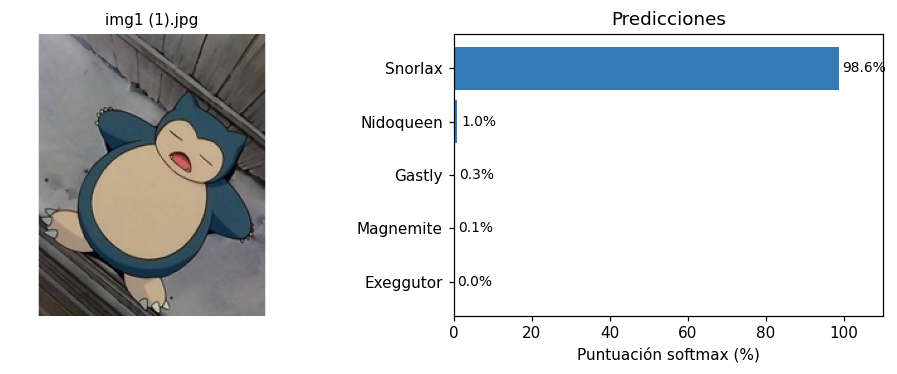

In [77]:
predictions = predict_uploaded_images(loaded_model, TOP_K)

In [78]:
display(predictions.round({"score_percent": 2}))

,filename,rank,pokemon,score_percent
0,img1 (1).jpg,1,Snorlax,98.589996
1,img1 (1).jpg,2,Nidoqueen,0.970000
2,img1 (1).jpg,3,Gastly,0.310000
3,img1 (1).jpg,4,Magnemite,0.100000
4,img1 (1).jpg,5,Exeggutor,0.010000
